# W7D5_LAB_In_God_we_trust_everyone_else_bring_the_data
- Week 7 / Day 5
- Student: Andreas Papachristophorou
- Course: AI Consulting & Integration 2026-07
- Date: 2026-08-24
---

## Part 2: Pairwise Group Comparisons

## Step 4: Compare Groups Using t-tests

In [3]:
import pandas as pd
import numpy as np
from itertools import combinations
from scipy.stats import ttest_ind, fisher_exact, false_discovery_control

# Load the prepared dataset
file_path = "data/digital_marketing_campaign_dataset.csv"

df = pd.read_csv(file_path)

# Check that the data loaded correctly
print(df.shape)
display(df.head())

(8000, 20)


,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1


In [4]:
# Keep only valid conversion-rate values
conversion_data = df[["CampaignChannel", "ConversionRate"]].dropna()

# Get the unique channel names
channels = conversion_data["CampaignChannel"].unique()

# Store results for each pairwise comparison
t_test_results = []

for channel_a, channel_b in combinations(channels, 2):

    values_a = conversion_data.loc[
        conversion_data["CampaignChannel"] == channel_a,
        "ConversionRate"
    ]

    values_b = conversion_data.loc[
        conversion_data["CampaignChannel"] == channel_b,
        "ConversionRate"
    ]

    # Independent-samples t-test (Welch's version, unequal variances allowed)
    t_statistic, p_value = ttest_ind(
        values_a,
        values_b,
        equal_var=False
    )

    mean_a = values_a.mean()
    mean_b = values_b.mean()
    difference = mean_b - mean_a
    percent_difference = (difference / mean_a) * 100

    # Cohen's d effect size
    pooled_std = np.sqrt(
        (values_a.var(ddof=1) + values_b.var(ddof=1)) / 2
    )
    cohens_d = difference / pooled_std

    if abs(cohens_d) < 0.2:
        effect_size = "Negligible"
    elif abs(cohens_d) < 0.5:
        effect_size = "Small"
    elif abs(cohens_d) < 0.8:
        effect_size = "Medium"
    else:
        effect_size = "Large"

    t_test_results.append({
        "Channel_A": channel_a,
        "Channel_B": channel_b,
        "Mean_A_%": mean_a * 100,
        "Mean_B_%": mean_b * 100,
        "Difference_pp": difference * 100,
        "Percent_Difference": percent_difference,
        "T_Statistic": t_statistic,
        "P_Value": p_value,
        "Cohens_d": cohens_d,
        "Effect_Size": effect_size,
        "Significant_0.05": p_value < 0.05
    })

t_test_results_df = pd.DataFrame(t_test_results).round({
    "Mean_A_%": 2, "Mean_B_%": 2, "Difference_pp": 2,
    "Percent_Difference": 2, "T_Statistic": 3,
    "P_Value": 4, "Cohens_d": 3
})

display(t_test_results_df)

print("Total comparisons:", len(t_test_results_df))
print("Significant at p < 0.05 (uncorrected):", t_test_results_df["Significant_0.05"].sum())

,Channel_A,Channel_B,Mean_A_%,Mean_B_%,Difference_pp,Percent_Difference,T_Statistic,P_Value,Cohens_d,Effect_Size,Significant_0.05
0,Social Media,Email,10.66,10.49,-0.17,-1.56,0.841,0.4002,-0.030,Negligible,False
1,Social Media,PPC,10.66,10.41,-0.24,-2.27,1.240,0.2150,-0.044,Negligible,False
2,Social Media,Referral,10.66,10.31,-0.35,-3.28,1.815,0.0696,-0.064,Negligible,False
3,Social Media,SEO,10.66,10.35,-0.30,-2.83,1.520,0.1286,-0.055,Negligible,False
4,Email,PPC,10.49,10.41,-0.08,-0.72,0.388,0.6981,-0.014,Negligible,False
5,Email,Referral,10.49,10.31,-0.18,-1.75,0.957,0.3388,-0.033,Negligible,False
6,Email,SEO,10.49,10.35,-0.14,-1.29,0.685,0.4933,-0.025,Negligible,False
7,PPC,Referral,10.41,10.31,-0.11,-1.04,0.574,0.5661,-0.020,Negligible,False
8,PPC,SEO,10.41,10.35,-0.06,-0.58,0.309,0.7570,-0.011,Negligible,False
9,Referral,SEO,10.31,10.35,0.05,0.47,-0.249,0.8032,0.009,Negligible,False


Total comparisons: 10
Significant at p < 0.05 (uncorrected): 0


### T-test results: conversion rate

Ten pairwise Welch t-tests compared the mean conversion rate across the five campaign channels. None of the comparisons were statistically significant at the uncorrected 5% significance level; all p-values exceeded 0.05.

The smallest p-value was 0.0696 for Social Media versus Referral. Although Social Media's average conversion rate was 0.35 percentage points higher (10.66% versus 10.31%), this difference was not statistically significant.

All Cohen's d effect sizes were negligible (absolute values below 0.2). The observed difference is not practically meaningful because its Cohen's d value is negligible. The difference between channel averages is tiny relative to the normal variation in individual conversion rates.

No budget-allocation decision should be based on conversion rate alone.

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Use the channel names from the cleaned conversion-rate data
channels = sorted(conversion_data["CampaignChannel"].unique())

# Start a square matrix filled with 1.0 values
# The rows and columns are both the campaign channels
p_value_matrix = pd.DataFrame(
    1.0,
    index=channels,
    columns=channels
)

# Copy each p-value into both matching cells
for _, row in t_test_results_df.iterrows():
    channel_a = row["Channel_A"]
    channel_b = row["Channel_B"]
    p_value = row["P_Value"]

    p_value_matrix.loc[channel_a, channel_b] = p_value
    p_value_matrix.loc[channel_b, channel_a] = p_value

# Display the matrix before plotting, to check it
display(p_value_matrix.round(4))

,Email,PPC,Referral,SEO,Social Media
Email,1.0000,0.6981,0.3388,0.4933,0.4002
PPC,0.6981,1.0000,0.5661,0.7570,0.2150
Referral,0.3388,0.5661,1.0000,0.8032,0.0696
SEO,0.4933,0.7570,0.8032,1.0000,0.1286
Social Media,0.4002,0.2150,0.0696,0.1286,1.0000


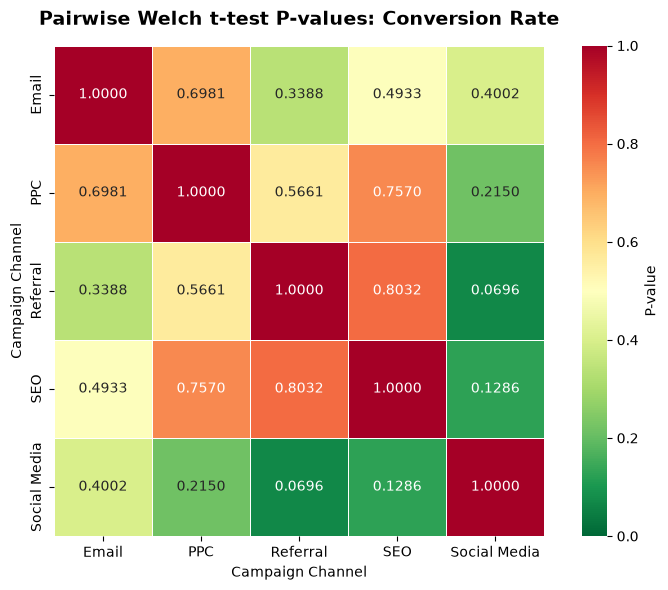

In [6]:
# Create the heatmap figure
plt.figure(figsize=(8, 6))

sns.heatmap(
    p_value_matrix,
    annot=True,
    fmt=".4f",
    cmap="RdYlGn_r",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar_kws={"label": "P-value"}
)

plt.title(
    "Pairwise Welch t-test P-values: Conversion Rate",
    fontsize=14,
    weight="bold",
    pad=15
)

plt.xlabel("Campaign Channel")
plt.ylabel("Campaign Channel")
plt.tight_layout()

# Create the graphs folder if it does not yet exist
graphs_folder = Path("graphs")
graphs_folder.mkdir(parents=True, exist_ok=True)

# Save the required figure
plt.savefig(
    graphs_folder / "metric_comparison_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 5: Compare Binary Outcomes Using Fisher's Exact

In [7]:
print(df.columns.tolist())

['CustomerID', 'Age', 'Gender', 'Income', 'CampaignChannel', 'CampaignType', 'AdSpend', 'ClickThroughRate', 'ConversionRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints', 'AdvertisingPlatform', 'AdvertisingTool', 'Conversion']


In [8]:
# Check that Conversion is a true binary column
print("Conversion values:")
print(df["Conversion"].value_counts(dropna=False).sort_index())

# Check whether WebsiteVisits can serve as total conversion opportunities
print("\nWebsiteVisits summary:")
display(df["WebsiteVisits"].describe())

# Count any impossible rows: a conversion without at least one visit
invalid_rows = df[df["Conversion"] > df["WebsiteVisits"]]

print("\nRows where Conversion > WebsiteVisits:", len(invalid_rows))

Conversion values:
Conversion
0     988
1    7012
Name: count, dtype: int64

WebsiteVisits summary:


count    8000.000000
mean       24.751625
std        14.312269
min         0.000000
25%        13.000000
50%        25.000000
75%        37.000000
max        49.000000
Name: WebsiteVisits, dtype: float64


Rows where Conversion > WebsiteVisits: 119


In [9]:
# Check that Conversion contains only 0 and 1
binary_data = df[
    ["CampaignChannel", "Conversion"]
].dropna()

# Summarize conversion outcomes by campaign channel
conversion_summary = binary_data.groupby("CampaignChannel").agg(
    Total_Customers=("Conversion", "count"),
    Conversions=("Conversion", "sum")
)

# Every row that is not a conversion is a non-conversion
conversion_summary["Non_Conversions"] = (
    conversion_summary["Total_Customers"]
    - conversion_summary["Conversions"]
)

# Calculate the conversion percentage for context
conversion_summary["Conversion_Rate_%"] = (
    conversion_summary["Conversions"]
    / conversion_summary["Total_Customers"]
    * 100
)

display(conversion_summary.round(2))

,Total_Customers,Conversions,Non_Conversions,Conversion_Rate_%
CampaignChannel,,,,
Email,1557,1355,202,87.03
PPC,1655,1461,194,88.28
Referral,1719,1518,201,88.31
SEO,1550,1359,191,87.68
Social Media,1519,1319,200,86.83


### Binary conversion-outcome setup

The `Conversion` variable is binary: 0 represents a non-conversion and 1 represents a conversion. Although website visits might seem like a possible denominator, 119 records have a conversion value greater than website visits. Therefore, website visits cannot validly be used to calculate non-conversions.

For Fisher's exact tests, each dataset row is treated as one customer-level conversion opportunity. Total customers per channel are the attempts; conversions are rows with `Conversion = 1`; and non-conversions are rows with `Conversion = 0`.

In [10]:
# Use the same channel order as the previous analysis
channels = sorted(conversion_summary.index)

# Store results from every channel pair
fisher_results = []

for channel_a, channel_b in combinations(channels, 2):

    # Get conversion counts for each channel
    conversions_a = conversion_summary.loc[channel_a, "Conversions"]
    non_conversions_a = conversion_summary.loc[channel_a, "Non_Conversions"]

    conversions_b = conversion_summary.loc[channel_b, "Conversions"]
    non_conversions_b = conversion_summary.loc[channel_b, "Non_Conversions"]

    # Build the required 2-by-2 contingency table
    contingency_table = [
        [conversions_a, non_conversions_a],
        [conversions_b, non_conversions_b]
    ]

    # Run a two-sided Fisher's exact test
    odds_ratio, p_value = fisher_exact(
        contingency_table,
        alternative="two-sided"
    )

    # Calculate customer-level conversion rates
    rate_a = conversions_a / (
        conversions_a + non_conversions_a
    )

    rate_b = conversions_b / (
        conversions_b + non_conversions_b
    )

    # Store the comparison result
    fisher_results.append({
        "Channel_A": channel_a,
        "Channel_B": channel_b,
        "Conversions_A": conversions_a,
        "Customers_A": conversions_a + non_conversions_a,
        "Rate_A_%": rate_a * 100,
        "Conversions_B": conversions_b,
        "Customers_B": conversions_b + non_conversions_b,
        "Rate_B_%": rate_b * 100,
        "Difference_pp": (rate_b - rate_a) * 100,
        "Odds_Ratio_A_vs_B": odds_ratio,
        "P_Value": p_value,
        "Significant_0.05": p_value < 0.05
    })

# Turn the list of results into a DataFrame
fisher_results_df = pd.DataFrame(fisher_results).round({
    "Rate_A_%": 2,
    "Rate_B_%": 2,
    "Difference_pp": 2,
    "Odds_Ratio_A_vs_B": 3,
    "P_Value": 4
})

display(fisher_results_df)

print("Total comparisons:", len(fisher_results_df))
print(
    "Significant at p < 0.05 (uncorrected):",
    fisher_results_df["Significant_0.05"].sum()
)

,Channel_A,Channel_B,Conversions_A,Customers_A,Rate_A_%,Conversions_B,Customers_B,Rate_B_%,Difference_pp,Odds_Ratio_A_vs_B,P_Value,Significant_0.05
0,Email,PPC,1355,1557,87.03,1461,1655,88.28,1.25,0.891,0.2834,False
1,Email,Referral,1355,1557,87.03,1518,1719,88.31,1.28,0.888,0.2868,False
2,Email,SEO,1355,1557,87.03,1359,1550,87.68,0.65,0.943,0.5899,False
3,Email,Social Media,1355,1557,87.03,1319,1519,86.83,-0.19,1.017,0.9148,False
4,PPC,Referral,1461,1655,88.28,1518,1719,88.31,0.03,0.997,1.0000,False
5,PPC,SEO,1461,1655,88.28,1359,1550,87.68,-0.60,1.058,0.6248,False
6,PPC,Social Media,1461,1655,88.28,1319,1519,86.83,-1.44,1.142,0.2358,False
7,Referral,SEO,1518,1719,88.31,1359,1550,87.68,-0.63,1.061,0.5901,False
8,Referral,Social Media,1518,1719,88.31,1319,1519,86.83,-1.47,1.145,0.2189,False
9,SEO,Social Media,1359,1550,87.68,1319,1519,86.83,-0.84,1.079,0.5159,False


Total comparisons: 10
Significant at p < 0.05 (uncorrected): 0
